In [1]:
import pandas as pd
import matplotlib. pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import warnings
warnings.filterwarnings("ignore")
from sklearn.preprocessing import LabelEncoder
from sklearn.pipeline import Pipeline

In [2]:
lung_data = pd.read_csv("survey lung cancer.csv")

In [3]:
lung_data.head()

,GENDER,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL CONSUMING,COUGHING,SHORTNESS OF BREATH,SWALLOWING DIFFICULTY,CHEST PAIN,LUNG_CANCER
0,M,69,1,2,2,1,1,2,1,2,2,2,2,2,2,YES
1,M,74,2,1,1,1,2,2,2,1,1,1,2,2,2,YES
2,F,59,1,1,1,2,1,2,1,2,1,2,2,1,2,NO
3,M,63,2,2,2,1,1,1,1,1,2,1,1,2,2,NO
4,F,63,1,2,1,1,1,1,1,2,1,2,2,1,1,NO


In [4]:
lung_data.shape

(309, 16)

In [5]:
lung_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 309 entries, 0 to 308
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   GENDER                 309 non-null    object
 1   AGE                    309 non-null    int64 
 2   SMOKING                309 non-null    int64 
 3   YELLOW_FINGERS         309 non-null    int64 
 4   ANXIETY                309 non-null    int64 
 5   PEER_PRESSURE          309 non-null    int64 
 6   CHRONIC DISEASE        309 non-null    int64 
 7   FATIGUE                309 non-null    int64 
 8   ALLERGY                309 non-null    int64 
 9   WHEEZING               309 non-null    int64 
 10  ALCOHOL CONSUMING      309 non-null    int64 
 11  COUGHING               309 non-null    int64 
 12  SHORTNESS OF BREATH    309 non-null    int64 
 13  SWALLOWING DIFFICULTY  309 non-null    int64 
 14  CHEST PAIN             309 non-null    int64 
 15  LUNG_CANCER            

In [6]:
lung_data.describe()

,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL CONSUMING,COUGHING,SHORTNESS OF BREATH,SWALLOWING DIFFICULTY,CHEST PAIN
count,309.000000,309.000000,309.000000,309.000000,309.000000,309.000000,309.000000,309.000000,309.000000,309.000000,309.000000,309.000000,309.000000,309.000000
mean,62.673139,1.563107,1.569579,1.498382,1.501618,1.504854,1.673139,1.556634,1.556634,1.556634,1.579288,1.640777,1.469256,1.556634
std,8.210301,0.496806,0.495938,0.500808,0.500808,0.500787,0.469827,0.497588,0.497588,0.497588,0.494474,0.480551,0.499863,0.497588
min,21.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,57.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
50%,62.000000,2.000000,2.000000,1.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,1.000000,2.000000
75%,69.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000
max,87.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000


In [ ]:
label_encoder = LabelEncoder()
lung_data['GENDER'] = label_encoder.fit_transform(lung_data['GENDER'])
lung_data['LUNG_CANCER'] = label_encoder.fit_transform(lung_data['LUNG_CANCER'])

In [9]:
lung_data.head()

,GENDER,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL CONSUMING,COUGHING,SHORTNESS OF BREATH,SWALLOWING DIFFICULTY,CHEST PAIN,LUNG_CANCER
0,1,69,1,2,2,1,1,2,1,2,2,2,2,2,2,1
1,1,74,2,1,1,1,2,2,2,1,1,1,2,2,2,1
2,0,59,1,1,1,2,1,2,1,2,1,2,2,1,2,0
3,1,63,2,2,2,1,1,1,1,1,2,1,1,2,2,0
4,0,63,1,2,1,1,1,1,1,2,1,2,2,1,1,0


In [10]:
lung_data.isnull().sum()

GENDER                   0
AGE                      0
SMOKING                  0
YELLOW_FINGERS           0
ANXIETY                  0
PEER_PRESSURE            0
CHRONIC DISEASE          0
FATIGUE                  0
ALLERGY                  0
WHEEZING                 0
ALCOHOL CONSUMING        0
COUGHING                 0
SHORTNESS OF BREATH      0
SWALLOWING DIFFICULTY    0
CHEST PAIN               0
LUNG_CANCER              0
dtype: int64

In [11]:
lung_data.dtypes

GENDER                   int32
AGE                      int64
SMOKING                  int64
YELLOW_FINGERS           int64
ANXIETY                  int64
PEER_PRESSURE            int64
CHRONIC DISEASE          int64
FATIGUE                  int64
ALLERGY                  int64
WHEEZING                 int64
ALCOHOL CONSUMING        int64
COUGHING                 int64
SHORTNESS OF BREATH      int64
SWALLOWING DIFFICULTY    int64
CHEST PAIN               int64
LUNG_CANCER              int32
dtype: object

In [12]:
#the info() method prints information of the database
lung_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 309 entries, 0 to 308
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   GENDER                 309 non-null    int32
 1   AGE                    309 non-null    int64
 2   SMOKING                309 non-null    int64
 3   YELLOW_FINGERS         309 non-null    int64
 4   ANXIETY                309 non-null    int64
 5   PEER_PRESSURE          309 non-null    int64
 6   CHRONIC DISEASE        309 non-null    int64
 7   FATIGUE                309 non-null    int64
 8   ALLERGY                309 non-null    int64
 9   WHEEZING               309 non-null    int64
 10  ALCOHOL CONSUMING      309 non-null    int64
 11  COUGHING               309 non-null    int64
 12  SHORTNESS OF BREATH    309 non-null    int64
 13  SWALLOWING DIFFICULTY  309 non-null    int64
 14  CHEST PAIN             309 non-null    int64
 15  LUNG_CANCER            309 non-null    i

In [13]:
X = lung_data.drop(columns=['LUNG_CANCER'],axis=1)
Y = lung_data['LUNG_CANCER']

In [14]:
#Splitting the Dataset: Training and Testing
x_train,x_test,y_train,y_test = train_test_split(X,Y,test_size=1/3,random_state=0)

In [15]:
lung_data['LUNG_CANCER'].value_counts()

LUNG_CANCER
1    270
0     39
Name: count, dtype: int64

In [16]:
len(lung_data)

309

In [17]:
len(x_test)

103

In [18]:
len(x_train)

206

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier

In [20]:
pipe_log_reg=Pipeline([("log_reg_classifier",LogisticRegression())])

pipe_knn=Pipeline([("knn_classifier",KNeighborsClassifier(n_neighbors = 3, metric = "minkowski", p = 2))])

pipe_svc=Pipeline([("svc_classifier",OneVsRestClassifier(BaggingClassifier(SVC(C=10,kernel='rbf',random_state=9,probability=True),n_jobs=-1)))])

pipe_dt=Pipeline([("dt_classifier", DecisionTreeClassifier(random_state = 0,criterion = "entropy"))])

pipe_gau_nb=Pipeline([("gau_nb_classifier",GaussianNB())])

pipe_rf=Pipeline([("rf_classifier",RandomForestClassifier(n_estimators=100, random_state=42))])

In [21]:
pipelines=[pipe_log_reg,pipe_knn,pipe_svc,pipe_dt,pipe_gau_nb,pipe_rf]
model_names=["Logistic Regression","KNeighbors Classifier","Support Vector Classifier","DecisionTree Classifier","GaussianNB","RandomForestClassifier"]

In [22]:
for pipe in pipelines:
    pipe.fit(x_train, y_train)

In [23]:
score=[]
def model_eval(model_name):
    i=0
    global score
    for pipe in pipelines:
        print(f"Model: {model_name[i]}\n")
        pred = pipe.predict(x_test)
        
        accuracy = accuracy_score(y_test, pred)
        classification_rep = classification_report(y_test, pred)
        conf_matrix = confusion_matrix(y_test, pred)
        score.append(accuracy)
        
        print(f"Accuracy of {model_name[i]}")
        print(f"Accuracy: {accuracy:.4f}")
        print("\nConfusion Matrix:\n", conf_matrix)
        print("\nClassification Report:\n", classification_rep)
        print("------------------------------------------------------")
        i+=1

In [24]:
model_eval(model_names)

Model: Logistic Regression

Accuracy of Logistic Regression
Accuracy: 0.9029

Confusion Matrix:
 [[ 8  8]
 [ 2 85]]

Classification Report:
               precision    recall  f1-score   support

           0       0.80      0.50      0.62        16
           1       0.91      0.98      0.94        87

    accuracy                           0.90       103
   macro avg       0.86      0.74      0.78       103
weighted avg       0.90      0.90      0.89       103

------------------------------------------------------
Model: KNeighbors Classifier

Accuracy of KNeighbors Classifier
Accuracy: 0.8738

Confusion Matrix:
 [[ 4 12]
 [ 1 86]]

Classification Report:
               precision    recall  f1-score   support

           0       0.80      0.25      0.38        16
           1       0.88      0.99      0.93        87

    accuracy                           0.87       103
   macro avg       0.84      0.62      0.66       103
weighted avg       0.87      0.87      0.84       103

-----

In [25]:
score

[0.9029126213592233,
 0.8737864077669902,
 0.8446601941747572,
 0.8640776699029126,
 0.8640776699029126,
 0.8932038834951457]

In [26]:
max(score)

0.9029126213592233

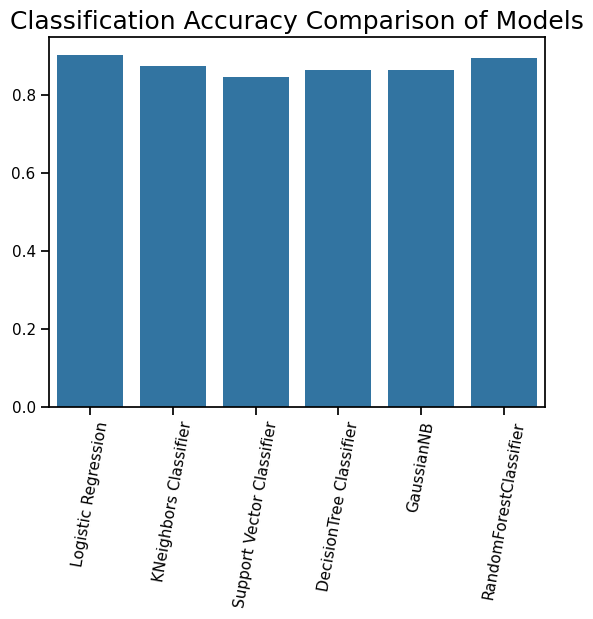

In [27]:
sns.set(context='notebook', style=None, palette='tab10')
ax = sns.barplot(x=model_names, y=score)
ax.set_title('Classification Accuracy Comparison of Models', fontsize=18)
for item in ax.get_xticklabels():
    item.set_rotation(80)
for p in ax.patches:
        ax.annotate('{:}%'.format(p.get_height()), (p.get_x()+0.01, p.get_height()+1))

In [28]:
model = LogisticRegression()
model.fit(x_train,y_train)

LogisticRegression()

In [29]:
import pickle
filename='Lung Cancer.pkl'
pickle.dump(model,open(filename,'wb'))

In [32]:
#making a predictive system
input_data=(1,60,2,2,2,1,1,1,1,1,2,1,1,2,2)

#changing the input data to numpy array
input_data_as_numpy_array=np.asarray(input_data)

#reshape the array as we are predicting for one instance
input_data_reshaped=input_data_as_numpy_array.reshape(1,-1)

prediction=model.predict(input_data_reshaped)
print(prediction)

if(prediction[0]==0):
    print("The person doesn\'t suffer lung cancer.")
else:
    print("The person suffers lung cancer.")

[1]
The person suffers lung cancer.


In [33]:
#making a predictive system
input_data=(1,63,2,1,1,2,1,1,1,1,1,2,2,1,1)

#changing the input data to numpy array
input_data_as_numpy_array=np.asarray(input_data)

#reshape the array as we are predicting for one instance
input_data_reshaped=input_data_as_numpy_array.reshape(1,-1)

prediction=model.predict(input_data_reshaped)
print(prediction)

if(prediction[0]==0):
    print("The person doesn\'t suffer lung cancer.")
else:
    print("The person suffers lung cancer.")

[0]
The person doesn't suffer lung cancer.
